In [1]:
#imports
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", category=UserWarning)   # harmless joblib/sklearn notices
RANDOM_STATE = 42
TARGET_RECALL = 0.85
GAP_LIMIT = 0.05       # largest acceptable recall gap between groups

In [2]:
#LOAD THE DATA
df = pd.read_csv("../data/data.csv", sep=";")
if df.shape[1] == 1:              # Kaggle version uses commas
    df = pd.read_csv("../data/data.csv")
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
#DROPOUT LABEL AND BASE RATES
df["dropout"] = (df["Target"] == "Dropout").astype(int)
df["Gender name"] = df["Gender"].map({0: "Female", 1: "Male"})
df["Age band"] = pd.cut(df["Age at enrollment"], [0, 20, 24, 200],
                        labels=["20 or under", "21-24", "25 and over"]).astype(str)
print(df["Target"].value_counts())
print("\nDropout rate:", round(df["dropout"].mean(), 3))
print(df.groupby("Gender name")["dropout"].mean().round(3))
print(df.groupby("Age band")["dropout"].mean().round(3))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Dropout rate: 0.321
Gender name
Female    0.251
Male      0.451
Name: dropout, dtype: float64
Age band
20 or under    0.212
21-24          0.337
25 and over    0.554
Name: dropout, dtype: float64


In [4]:

sem1 = "Curricular units 1st sem"
enrolled = df[f"{sem1} (enrolled)"]

df["sem1_approval_rate"] = np.where(enrolled > 0, df[f"{sem1} (approved)"] / enrolled, 0)
df["sem1_pass_per_exam"] = np.where(df[f"{sem1} (evaluations)"] > 0,
                                    df[f"{sem1} (approved)"] / df[f"{sem1} (evaluations)"], 0)
df["sem1_no_exam_share"] = np.where(enrolled > 0, df[f"{sem1} (without evaluations)"] / enrolled, 0)
df["sem1_failed_units"] = (enrolled - df[f"{sem1} (approved)"]).clip(lower=0)
df["fee_problem"] = ((df["Debtor"] == 1) | (df["Tuition fees up to date"] == 0)).astype(int)
df["grade_gap"] = df["Admission grade"] - df["Previous qualification (grade)"]

In [5]:
categorical_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
                    "Mother's qualification", "Father's qualification",
                    "Mother's occupation", "Father's occupation"]

numeric_cols = ["Application order", "Daytime/evening attendance", "Previous qualification (grade)",
                "Admission grade", "Displaced", "Educational special needs", "Debtor",
                "Tuition fees up to date", "Scholarship holder", "Age at enrollment", "International",
                "Unemployment rate", "Inflation rate", "GDP",
                f"{sem1} (credited)", f"{sem1} (enrolled)", f"{sem1} (evaluations)",
                f"{sem1} (approved)", f"{sem1} (grade)", f"{sem1} (without evaluations)",
                "sem1_approval_rate", "sem1_pass_per_exam", "sem1_no_exam_share",
                "sem1_failed_units", "fee_problem", "grade_gap"]

features = categorical_cols + numeric_cols
X = df[features].copy()
for c in categorical_cols:
    X[c] = X[c].astype("category")
y = df["dropout"]
gender = df["Gender name"]   # used only for fairness, not as a feature
age_band = df["Age band"]    # used only for fairness (age itself is a feature)
print("Features used:", len(features))

Features used: 34


In [6]:
#TRAIN TEST AND SPLIT
X_train, X_test, y_train, y_test, g_train, g_test, a_train, a_test = train_test_split(
    X, y, gender, age_band, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3539, 34)  Test: (885, 34)


In [7]:
#TUNED GRADIENT BOOSTING
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced",
                                      early_stopping=False, random_state=RANDOM_STATE)

param_dist = {"learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
              "max_iter": [200, 300, 400, 600],
              "max_leaf_nodes": [8, 15, 31],
              "min_samples_leaf": [10, 20, 40, 60],
              "l2_regularization": [0.0, 0.1, 0.5, 1.0],
              "max_features": [0.5, 0.7, 1.0]}

search = RandomizedSearchCV(base, param_dist, n_iter=25, scoring="roc_auc", cv=cv,
                            n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
model = search.best_estimator_

Best CV ROC-AUC: 0.9001
Best parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 300, 'max_features': 0.5, 'learning_rate': 0.02, 'l2_regularization': 0.0}


In [8]:
#FAIRNESS CONSTRAINT: EQUAL OPPORTUNITY THRESHOLD
def group_report(y_true, y_pred, group):
    rows = []
    for g in sorted(np.unique(group), key=str):
        m = (group == g)
        tn, fp, fn, tp = confusion_matrix(y_true[m], y_pred[m], labels=[0, 1]).ravel()
        rows.append({"Group": g, "Students": int(m.sum()), "Dropouts": int(tp + fn),
                     "Selection rate": y_pred[m].mean(),
                     "Recall (TPR)": tp / (tp + fn),
                     "False positive rate": fp / (fp + tn),
                     "Precision": tp / (tp + fp) if (tp + fp) else 0,
                     "Accuracy": (tp + tn) / m.sum()})
    return pd.DataFrame(rows).set_index("Group").round(3)


def recall_gap(y_true, y_pred, group):
    r = [y_pred[(group == g) & (y_true == 1)].mean() for g in np.unique(group)]
    return max(r) - min(r)


def bootstrap_gap(y_true, y_pred, group, n=2000, seed=RANDOM_STATE):
    """95% interval for the recall gap: the test set is small, so gaps of a few points can be noise."""
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        gaps.append(recall_gap(y_true[i], y_pred[i], group[i]))
    return np.percentile(gaps, [2.5, 97.5]).round(3)


def threshold_for_recall(y_true, prob, target):
    """Highest cut-off that still catches at least `target` of the dropouts."""
    for t in np.arange(0.95, 0.04, -0.01):
        if recall_score(y_true, (prob >= t).astype(int)) >= target:
            return round(float(t), 2)
    return 0.05


# Out-of-fold predictions on the training set (the test set is never used to choose thresholds).
# Note: the same folds were used for tuning, so these are slightly optimistic; the test set stays clean.
oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Step 1: one threshold for everyone, aimed at the same recall target
SINGLE_T = threshold_for_recall(y_train.values, oof_prob, TARGET_RECALL)
oof_single = (oof_prob >= SINGLE_T).astype(int)
attributes = {"Gender": (g_train.values, g_test.values), "Age band": (a_train.values, a_test.values)}
oof_gaps = {name: recall_gap(y_train.values, oof_single, tr) for name, (tr, _) in attributes.items()}
print(f"Single threshold {SINGLE_T}: out-of-fold recall gap ->", {k: round(float(v), 3) for k, v in oof_gaps.items()})

# Step 2: constrain only the attributes whose gap is above the limit (on ~1,100 training dropouts)
constrained = [name for name, gap in oof_gaps.items() if gap > GAP_LIMIT]
print("Attributes that need the constraint:", constrained or "none")

def constraint_group(tr_or_te):
    idx = 0 if tr_or_te == "train" else 1
    if not constrained:
        return np.full(len(y_train if idx == 0 else y_test), "All")
    parts = [attributes[name][idx] for name in constrained]
    return pd.Series(parts[0]).str.cat(parts[1:], sep=", ").values if len(parts) > 1 else parts[0]

group_train, group_test = constraint_group("train"), constraint_group("test")
thresholds = {g: threshold_for_recall(y_train.values[group_train == g], oof_prob[group_train == g], TARGET_RECALL)
              for g in np.unique(group_train)}
print("Decision thresholds ->", thresholds)

Single threshold 0.27: out-of-fold recall gap -> {'Gender': 0.058, 'Age band': 0.16}
Attributes that need the constraint: ['Gender', 'Age band']
Decision thresholds -> {'Female, 20 or under': 0.13, 'Female, 21-24': 0.27, 'Female, 25 and over': 0.59, 'Male, 20 or under': 0.21, 'Male, 21-24': 0.33, 'Male, 25 and over': 0.6}


Accuracy         : 0.745
Precision        : 0.568
Recall           : 0.852
F1-score         : 0.682
ROC-AUC          : 0.910
Average precision: 0.877
Flagged          : 48.1% of students


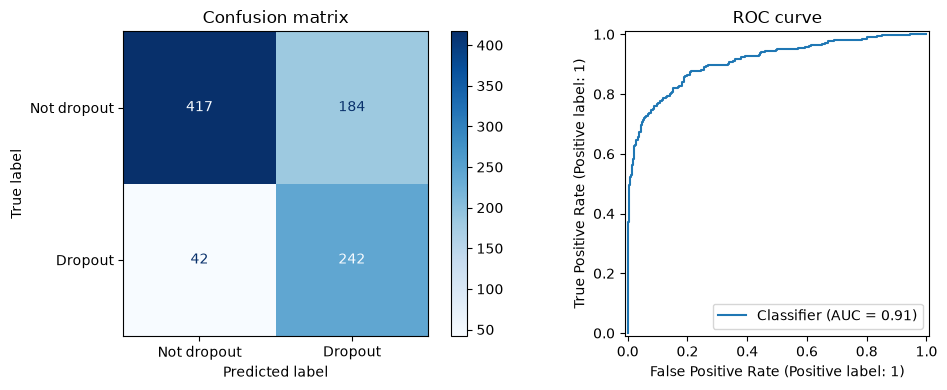

In [9]:
#OVERALL PERFORMANCE
y_prob = model.predict_proba(X_test)[:, 1]
thr_vec = pd.Series(group_test).map(thresholds).values
y_pred = (y_prob >= thr_vec).astype(int)

print(f"Accuracy         : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision        : {precision_score(y_test, y_pred):.3f}")
print(f"Recall           : {recall_score(y_test, y_pred):.3f}")
print(f"F1-score         : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC          : {roc_auc_score(y_test, y_prob):.3f}")
print(f"Average precision: {average_precision_score(y_test, y_prob):.3f}")
print(f"Flagged          : {y_pred.mean():.1%} of students")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Not dropout", "Dropout"]).plot(cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1]); ax[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

In [10]:
#FAIRNESS AUDIT: SINGLE THRESHOLD VS. FAIRNESS-CONSTRAINED
# Fair comparison: the single threshold is chosen the same way (same recall target), not fixed at 0.5
options = {"Single threshold 0.5": (y_prob >= 0.5).astype(int),
           f"Single threshold {SINGLE_T} (same recall target)": (y_prob >= SINGLE_T).astype(int),
           "Fairness-constrained thresholds": y_pred}

reports = {}
for name, (_, te) in attributes.items():
    print(f"=== {name} ===")
    for opt, pred in options.items():
        reports[(name, opt)] = group_report(y_test.values, pred, te)
        print(f"{opt}:\n{reports[(name, opt)]}\n")

rows = {}
for opt, pred in options.items():
    row = {"Overall recall": recall_score(y_test, pred), "Overall precision": precision_score(y_test, pred),
           "Overall F1": f1_score(y_test, pred), "Flagged": pred.mean()}
    for name, (_, te) in attributes.items():
        lo, hi = bootstrap_gap(y_test.values, pred, te)
        row[f"{name} recall gap"] = recall_gap(y_test.values, pred, te)
        row[f"{name} gap 95% interval"] = f"{lo} to {hi}"
    rows[opt] = row
summary = pd.DataFrame(rows).T
numbers = [col for col in summary.columns if "interval" not in col]
summary[numbers] = summary[numbers].astype(float).round(3)
print(summary.to_string())

=== Gender ===
Single threshold 0.5:
        Students  Dropouts  Selection rate  Recall (TPR)  False positive rate  Precision  Accuracy
Group                                                                                             
Female       564       138           0.257         0.761                0.094      0.724     0.871
Male         321       146           0.433         0.781                0.143      0.820     0.822

Single threshold 0.27 (same recall target):
        Students  Dropouts  Selection rate  Recall (TPR)  False positive rate  Precision  Accuracy
Group                                                                                             
Female       564       138           0.369         0.877                0.204      0.582     0.816
Male         321       146           0.545         0.877                0.269      0.731     0.798

Fairness-constrained thresholds:
        Students  Dropouts  Selection rate  Recall (TPR)  False positive rate  Precision  Ac

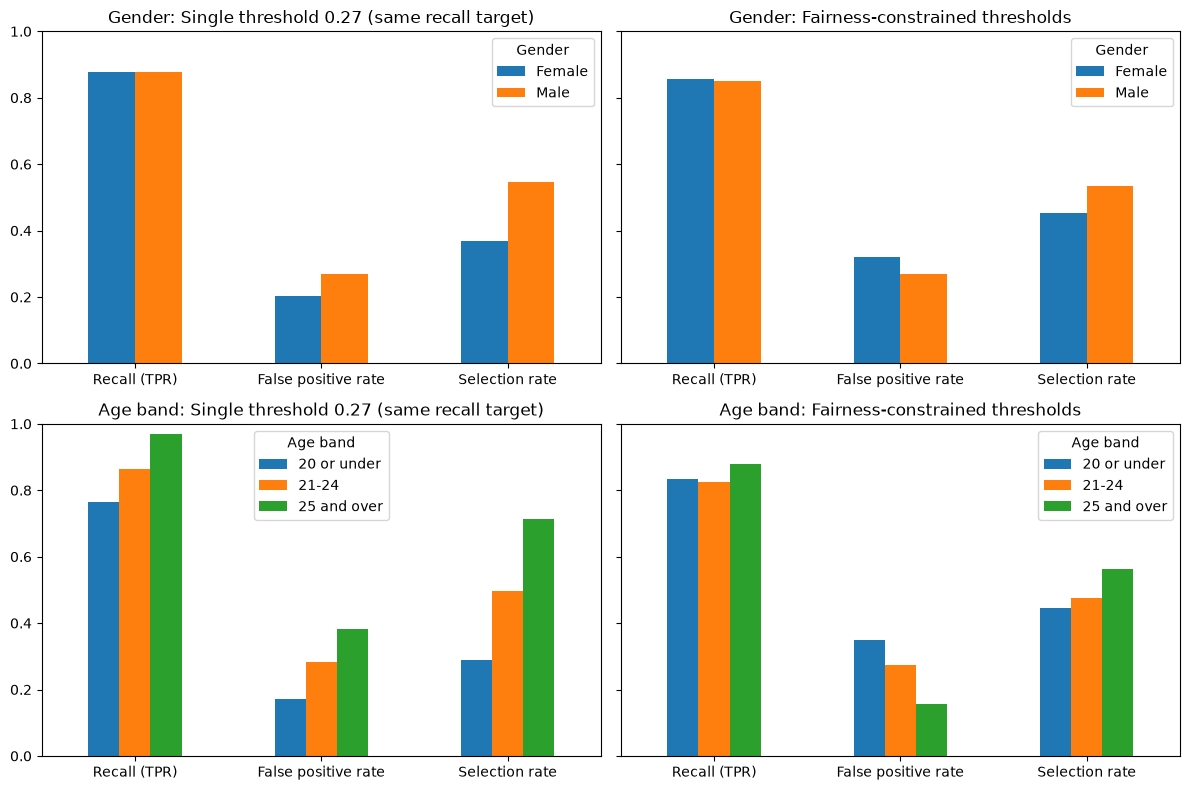

In [11]:
#FAIRNESS CHART
same_recall = f"Single threshold {SINGLE_T} (same recall target)"
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for row, name in enumerate(attributes):
    for col, opt in enumerate([same_recall, "Fairness-constrained thresholds"]):
        reports[(name, opt)][["Recall (TPR)", "False positive rate", "Selection rate"]].T.plot(kind="bar", rot=0, ax=ax[row, col])
        ax[row, col].set_title(f"{name}: {opt}")
        ax[row, col].set_ylim(0, 1); ax[row, col].legend(title=name)
plt.tight_layout(); plt.show()

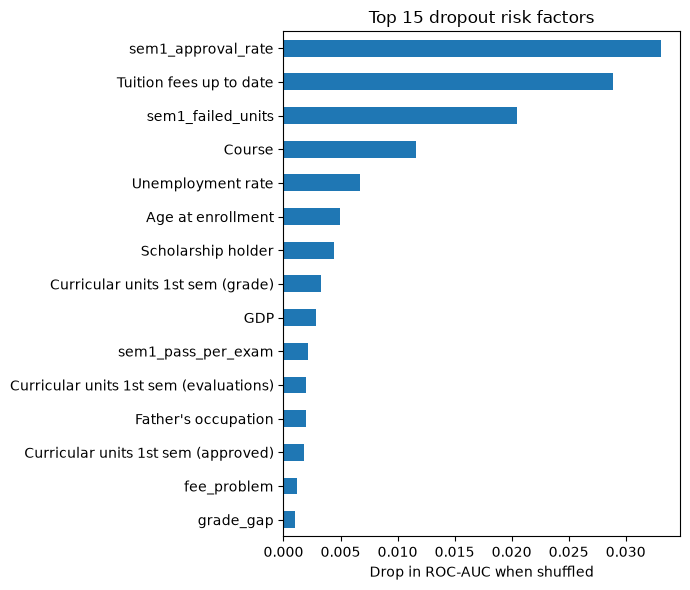

In [12]:
#TOP RISK FACTORS
imp = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                             random_state=RANDOM_STATE, n_jobs=-1)
top = pd.Series(imp.importances_mean, index=features).sort_values(ascending=False).head(15)
top.sort_values().plot(kind="barh", figsize=(7, 6))
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title("Top 15 dropout risk factors")
plt.tight_layout(); plt.show()


In [13]:
#EARLY WARNING OUTPUTS FOR ADVISOR
def risk_level(p, t):
    if p >= max(0.7, t + 0.2): return "High"
    if p >= t: return "Medium"
    return "Low"

alerts = pd.DataFrame({"Gender": g_test.values, "Age band": a_test.values,
                       "Dropout probability": y_prob.round(3),
                       "Risk level": [risk_level(p, t) for p, t in zip(y_prob, thr_vec)],
                       "Actual": y_test.map({0: "Not dropout", 1: "Dropout"}).values})

print(alerts["Risk level"].value_counts())
print(pd.crosstab(alerts["Risk level"], alerts["Actual"]))
alerts.sort_values("Dropout probability", ascending=False).head(10)

Risk level
Low       459
Medium    221
High      205
Name: count, dtype: int64
Actual      Dropout  Not dropout
Risk level                      
High            185           20
Low              42          417
Medium           57          164


,Gender,Age band,Dropout probability,Risk level,Actual
860,Male,25 and over,0.995,High,Dropout
90,Male,25 and over,0.995,High,Dropout
505,Male,25 and over,0.994,High,Dropout
9,Female,25 and over,0.994,High,Dropout
629,Male,21-24,0.993,High,Dropout
734,Female,25 and over,0.992,High,Dropout
550,Female,25 and over,0.992,High,Dropout
271,Female,25 and over,0.991,High,Dropout
680,Male,25 and over,0.991,High,Dropout
83,Female,25 and over,0.991,High,Dropout
